# Análisis Estadístico de Temperatura Ambiente — Cundinamarca

Notebook reproducible para el análisis estadístico del dataset
`Temperatura_Ambiente_del_Aire_Cundinamarca_desde_01012024`.

**Objetivo:** extraer conclusiones técnicas útiles para la gestión ambiental,
agrícola y territorial a nivel municipal, a partir de la temperatura ambiente
(°C) registrada por sensores en el departamento de Cundinamarca desde el 01/01/2024.

**Contenido:**

1. Importación, validación y limpieza de datos (con resumen de calidad).
2. Estadísticas descriptivas y de dispersión (por municipio, mes y estación).
3. Evaluación de normalidad y comparación de temperatura entre municipios.
4. Tendencia temporal (media móvil y descomposición estacional).
5. Visualizaciones (exportadas a `outputs/figures/`).
6. Conclusiones técnicas.


In [2]:
# ============================================================
# Importación de librerías y configuración general.
# ============================================================
import os
import unicodedata
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
from statsmodels.tsa.seasonal import seasonal_decompose

# Tema visual y resolución de las figuras exportadas.
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 150
plt.rcParams["savefig.dpi"] = 150
plt.rcParams["savefig.bbox"] = "tight"

# Semilla para reproducibilidad de muestreos y pruebas aleatorias.
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)


In [3]:
# ============================================================
# Definición de rutas del proyecto.
# El notebook asume que vive en <raiz>/notebooks/. Si se ejecuta
# desde la raíz del proyecto o desde notebooks/, la raíz se
# resuelve automáticamente.
# ============================================================
PROJECT_ROOT = Path(os.path.abspath("")).resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

RAW_DIR = PROJECT_ROOT / "data" / "raw"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
FIGURES_DIR = PROJECT_ROOT / "outputs" / "figures"

# Se crean las carpetas de salida en caso de que no existan.
for d in (RAW_DIR, PROCESSED_DIR, FIGURES_DIR):
    d.mkdir(parents=True, exist_ok=True)

print("PROJECT_ROOT :", PROJECT_ROOT)
print("RAW_DIR      :", RAW_DIR)
print("PROCESSED_DIR:", PROCESSED_DIR)
print("FIGURES_DIR  :", FIGURES_DIR)


PROJECT_ROOT : D:\Universidad\Alejandro\Taller_002
RAW_DIR      : D:\Universidad\Alejandro\Taller_002\data\raw
PROCESSED_DIR: D:\Universidad\Alejandro\Taller_002\data\processed
FIGURES_DIR  : D:\Universidad\Alejandro\Taller_002\outputs\figures


## 1. Importación y validación de datos

Se carga el CSV crudo desde `data/raw/`, se validan los tipos de datos, se
tratan nulos/duplicados/outliers y se deja un resumen de calidad de datos.


In [4]:
# ============================================================
# Localización y lectura del CSV crudo.
# ============================================================
raw_files = sorted(RAW_DIR.glob("*.csv"))
assert raw_files, f"No se encontró ningún CSV en {RAW_DIR}"
RAW_FILE = raw_files[0]
print("Archivo crudo:", RAW_FILE.name)

# Se leen solo las columnas necesarias (por rendimiento).
usecols = ["CodigoEstacion", "FechaObservacion", "ValorObservado", "Municipio", "NombreEstacion"]

# El CSV usa coma como separador y coma como separador decimal (los valores
# decimales vienen entre comillas), por lo que ValorObservado se lee como texto
# y se convierte a numérico en el paso siguiente.
df = pd.read_csv(
    RAW_FILE,
    usecols=usecols,
    dtype={"CodigoEstacion": str, "ValorObservado": str, "Municipio": str, "NombreEstacion": str},
)

print("Filas crudas leídas:", len(df))
df.head()


Archivo crudo: Temperatura_Ambiente_del_Aire_Cundianamarca_desde_01012024.csv
Filas crudas leídas: 1800319


,CodigoEstacion,FechaObservacion,ValorObservado,NombreEstacion,Municipio
0,3502500135,2024 Jan 01 03:12:00 PM,"25,6",GUAYABETAL POLLO OLIMPICO,GUAYABETAL
1,3502500135,2024 Jan 01 03:14:00 PM,"25,7",GUAYABETAL POLLO OLIMPICO,GUAYABETAL
2,3502500135,2024 Jan 01 03:16:00 PM,"25,7",GUAYABETAL POLLO OLIMPICO,GUAYABETAL
3,3502500135,2024 Jan 01 03:18:00 PM,"25,6",GUAYABETAL POLLO OLIMPICO,GUAYABETAL
4,0021205526,2024 Jan 01 03:20:00 PM,"19,34045",PEDRO PALO,TENA


In [5]:
# ============================================================
# Conversión de fecha y valor observado + validación de tipos.
# ============================================================
# La fecha viene en formato '2024 Jan 01 03:12:00 PM' (mes abreviado en inglés).
df["fecha"] = pd.to_datetime(
    df["FechaObservacion"], format="%Y %b %d %I:%M:%S %p", errors="coerce"
)

# El valor observado usa coma como separador decimal: se reemplaza por punto
# y se convierte a float.
df["temperatura"] = pd.to_numeric(
    df["ValorObservado"].astype(str).str.replace(",", "."), errors="coerce"
)

print("Tipos de datos tras la conversión:")
print(df.dtypes)
print("\nNulos por columna tras la conversión:")
print(df[["fecha", "temperatura"]].isna().sum())


Tipos de datos tras la conversión:
CodigoEstacion              object
FechaObservacion            object
ValorObservado              object
NombreEstacion              object
Municipio                   object
fecha               datetime64[ns]
temperatura                float64
dtype: object

Nulos por columna tras la conversión:
fecha          0
temperatura    0
dtype: int64


In [6]:
# ============================================================
# Normalización del nombre de municipio.
# Se eliminan tildes/acentos y se unifica a mayúsculas para agrupar
# etiquetas duplicadas por diferencias de formato (p.ej. 'ANAPOIMA' y
# 'Anapoima', o 'CHOACHÍ' y 'Choachí').
# ============================================================
def normalizar_texto(texto):
    texto = str(texto).strip()
    texto = unicodedata.normalize("NFD", texto)
    texto = "".join(c for c in texto if unicodedata.category(c) != "Mn")
    return texto.upper()

df["municipio"] = df["Municipio"].map(normalizar_texto)

print("Etiquetas de municipio originales:", df["Municipio"].nunique())
print("Municipios únicos tras normalización:", df["municipio"].nunique())
print(sorted(df["municipio"].unique()))


Etiquetas de municipio originales: 72
Municipios únicos tras normalización: 46
['ANAPOIMA', 'ANOLAIMA', 'BOGOTA D.C', 'BOJACA', 'CABRERA', 'CARMEN DE CARUPA', 'CHIA', 'CHOACHI', 'CHOCONTA', 'COGUA', 'CUCUNUBA', 'FACATATIVA', 'FUNZA', 'GIRARDOT', 'GUADUAS', 'GUASCA', 'GUAYABETAL', 'GUTIERREZ', 'JUNIN', 'LA CALERA', 'LA VEGA', 'MACHETA', 'MEDINA', 'MOSQUERA', 'NEMOCON', 'PACHO', 'PASCA', 'PUERTO SALGAR', 'PULI', 'QUEBRADANEGRA', 'SAN CAYETANO', 'SAN FRANCISCO', 'SIBATE', 'SILVANIA', 'SIMIJACA', 'SOACHA', 'SOPO', 'TABIO', 'TAUSA', 'TENA', 'UBATE', 'VILLAGOMEZ', 'VILLAPINZON', 'VILLETA', 'YACOPI', 'ZIPAQUIRA']


In [7]:
# ============================================================
# Tratamiento de nulos, duplicados y outliers + resumen de calidad.
# ============================================================
n_inicial = len(df)
fecha_nulos = int(df["fecha"].isna().sum())
temp_nulos = int(df["temperatura"].isna().sum())

# Duplicados exactos (retransmisiones del sensor): se eliminan.
n_duplicados = int(df.duplicated().sum())
df = df.drop_duplicates().copy()

# Se descartan filas con fecha o temperatura inválidas.
df = df.dropna(subset=["fecha", "temperatura"]).copy()

# Detección de outliers por método estadístico (IQR, factor 1.5), calculado
# POR MUNICIPIO: cada municipio tiene su propio clima, por lo que el umbral
# debe ser local y no global.
def es_outlier_iqr(serie):
    q1 = serie.quantile(0.25)
    q3 = serie.quantile(0.75)
    iqr = q3 - q1
    return (serie < q1 - 1.5 * iqr) | (serie > q3 + 1.5 * iqr)

df["outlier"] = df.groupby("municipio")["temperatura"].transform(es_outlier_iqr)
n_outliers = int(df["outlier"].sum())

df_clean = df.loc[~df["outlier"]].drop(columns=["outlier"]).copy()

# Resumen de calidad de datos.
print("===== RESUMEN DE CALIDAD DE DATOS =====")
print(f"Filas originales                 : {n_inicial}")
print(f"Nulos en fecha                   : {fecha_nulos}")
print(f"Nulos en temperatura             : {temp_nulos}")
print(f"Duplicados exactos eliminados    : {n_duplicados}")
print(f"Outliers (IQR 1.5 por municipio) : {n_outliers}")
print(f"Filas finales                    : {len(df_clean)}")
print(f"Municipios finales               : {df_clean['municipio'].nunique()}")
print(f"Estaciones finales               : {df_clean['CodigoEstacion'].nunique()}")
print(f"Rango de fechas                  : {df_clean['fecha'].min()}  a  {df_clean['fecha'].max()}")


===== RESUMEN DE CALIDAD DE DATOS =====
Filas originales                 : 1800319
Nulos en fecha                   : 0
Nulos en temperatura             : 0
Duplicados exactos eliminados    : 242886
Outliers (IQR 1.5 por municipio) : 9632
Filas finales                    : 1547801
Municipios finales               : 46
Estaciones finales               : 59
Rango de fechas                  : 2024-01-01 15:12:00  a  2026-09-26 23:00:00


In [8]:
# ============================================================
# Guardado del dataset limpio en data/processed/.
# Se exporta con separador decimal '.' para mayor portabilidad.
# ============================================================
df_clean = df_clean.sort_values(["municipio", "fecha"]).reset_index(drop=True)

salida = PROCESSED_DIR / "temperatura_cundinamarca_limpio.csv"
df_clean[["fecha", "municipio", "CodigoEstacion", "NombreEstacion", "temperatura"]].to_csv(
    salida, index=False
)
print("Dataset limpio guardado en:", salida)
print("Filas:", len(df_clean))


Dataset limpio guardado en: D:\Universidad\Alejandro\Taller_002\data\processed\temperatura_cundinamarca_limpio.csv
Filas: 1547801


## 2. Estadísticas descriptivas y de dispersión

Se calculan medidas de tendencia central (media, mediana, moda) y de dispersión
(varianza, desviación estándar, rango, IQR, coeficiente de variación) de la
temperatura, agregadas por municipio y por periodo temporal (mes y estación).


In [9]:
# ============================================================
# Estadísticas descriptivas agregadas por municipio.
# ============================================================
def rango(s):
    return s.max() - s.min()

def iqr(s):
    return s.quantile(0.75) - s.quantile(0.25)

def cv(s):
    # Coeficiente de variación (desviación estándar / media).
    return s.std() / s.mean() if s.mean() != 0 else np.nan

stats_mun = df_clean.groupby("municipio")["temperatura"].agg(
    n="count",
    media="mean",
    mediana="median",
    moda=lambda s: s.mode().iloc[0] if not s.mode().empty else np.nan,
    varianza="var",
    desviacion_estandar="std",
    rango=rango,
    iqr=iqr,
    coeficiente_variacion=cv,
).round(3)

print("Estadísticas descriptivas por municipio:")
stats_mun


Estadísticas descriptivas por municipio:


,n,media,mediana,moda,varianza,desviacion_estandar,rango,iqr,coeficiente_variacion
municipio,,,,,,,,,
ANAPOIMA,14845,25.073,24.300,21.400,11.729,3.425,17.900,5.500,0.137
ANOLAIMA,21570,18.694,18.550,18.600,5.530,2.352,13.100,3.400,0.126
BOGOTA D.C,772,16.932,16.300,15.200,6.738,2.596,12.700,4.000,0.153
BOJACA,14260,12.374,12.200,11.300,2.349,1.533,8.600,2.100,0.124
CABRERA,11954,15.363,15.300,15.100,4.913,2.217,11.800,2.900,0.144
CARMEN DE CARUPA,13929,11.427,10.600,9.300,11.350,3.369,19.400,4.900,0.295
CHIA,14912,13.981,13.500,12.400,11.983,3.462,20.300,5.100,0.248
CHOACHI,10207,8.906,8.600,7.700,4.177,2.044,11.500,2.900,0.229
CHOCONTA,2881,11.742,11.639,11.532,2.778,1.667,9.200,1.828,0.142


In [10]:
# ============================================================
# Estadísticas descriptivas globales (toda la muestra).
# ============================================================
def resumen_global(s):
    return pd.Series({
        "n": s.count(),
        "media": s.mean(),
        "mediana": s.median(),
        "moda": s.mode().iloc[0] if not s.mode().empty else np.nan,
        "varianza": s.var(),
        "desviacion_estandar": s.std(),
        "rango": s.max() - s.min(),
        "iqr": s.quantile(0.75) - s.quantile(0.25),
        "coeficiente_variacion": s.std() / s.mean(),
    })

resumen_global(df_clean["temperatura"]).round(3)


n                        1547801.000
media                         16.856
mediana                       17.400
moda                          18.300
varianza                      29.171
desviacion_estandar            5.401
rango                         40.200
iqr                            7.700
coeficiente_variacion          0.320
dtype: float64

In [11]:
# ============================================================
# Variables temporales: mes y estación climatológica.
# Para Cundinamarca se usa el régimen bimodal de lluvias (seca/lluvias).
# ============================================================
df_clean["mes"] = df_clean["fecha"].dt.month
df_clean["anio"] = df_clean["fecha"].dt.year

def estacion(mes):
    if mes in (12, 1, 2):
        return "Dic-Feb (seca)"
    if mes in (3, 4, 5):
        return "Mar-May (lluvias)"
    if mes in (6, 7, 8):
        return "Jun-Ago (seca)"
    return "Sep-Nov (lluvias)"

df_clean["estacion"] = df_clean["mes"].map(estacion)

# Estadísticas por mes.
stats_mes = df_clean.groupby("mes")["temperatura"].agg(
    n="count", media="mean", mediana="median",
    desviacion_estandar="std", minimo="min", maximo="max",
).round(3)
print("Estadísticas por mes:")
stats_mes


Estadísticas por mes:


,n,media,mediana,desviacion_estandar,minimo,maximo
mes,,,,,,
1,170378,16.925,17.5,5.593,0.4,37.9
2,117182,16.884,17.5,5.336,2.0,36.4
3,136412,18.069,18.8,5.415,2.2,36.3
4,108820,18.517,18.7,5.132,2.2,36.4
5,104910,18.337,18.5,4.646,2.6,37.2
6,138362,16.892,17.5,5.065,2.0,36.4
7,150972,15.191,15.0,5.022,1.9,38.0
8,119586,15.822,16.3,5.367,0.1,38.0
9,117117,16.685,17.1,5.809,2.2,40.2


In [12]:
# Estadísticas por estación climatológica.
stats_estacion = df_clean.groupby("estacion")["temperatura"].agg(
    n="count", media="mean", mediana="median", desviacion_estandar="std",
).round(3)
stats_estacion


,n,media,mediana,desviacion_estandar
estacion,,,,
Dic-Feb (seca),426273,16.781,17.338,5.517
Jun-Ago (seca),408920,15.951,16.500,5.190
Mar-May (lluvias),350142,18.288,18.600,5.110
Sep-Nov (lluvias),362466,16.581,17.100,5.493


## 3. Normalidad y comparación entre municipios

Se evalúa la normalidad de la temperatura por municipio con el test de
Shapiro-Wilk. Según el resultado, se elige entre ANOVA (grupos normales) o
Kruskal-Wallis (no normalidad) para comparar la temperatura entre municipios.


In [13]:
# ============================================================
# Test de normalidad (Shapiro-Wilk) por municipio.
# scipy.stats.shapiro exige n <= 5000, por lo que se usa una submuestra
# aleatoria de hasta 5000 observaciones por municipio (semilla fija para
# reproducibilidad).
# ============================================================
SHAPIRO_MAX = 5000
resultados = []
for muni, grupo in df_clean.groupby("municipio")["temperatura"]:
    muestra = grupo.sample(n=min(SHAPIRO_MAX, len(grupo)), random_state=RANDOM_STATE)
    w, p = stats.shapiro(muestra)
    resultados.append({
        "municipio": muni,
        "n_muestra": len(muestra),
        "W": round(w, 4),
        "p_valor": p,
        "normal": p > 0.05,
    })

normalidad = pd.DataFrame(resultados).set_index("municipio")
print("Shapiro-Wilk por municipio (alfa = 0.05):")
normalidad


Shapiro-Wilk por municipio (alfa = 0.05):


,n_muestra,W,p_valor,normal
municipio,,,,
ANAPOIMA,5000,0.9502,3.391092e-38,False
ANOLAIMA,5000,0.9862,1.061031e-21,False
BOGOTA D.C,772,0.9501,1.710797e-15,False
BOJACA,5000,0.9826,2.567837e-24,False
CABRERA,5000,0.9958,8.499939e-11,False
CARMEN DE CARUPA,5000,0.9763,4.615862e-28,False
CHIA,5000,0.9890,2.833791e-19,False
CHOACHI,5000,0.9817,6.579758e-25,False
CHOCONTA,2881,0.9852,9.279181e-17,False


In [14]:
# ============================================================
# Selección de la prueba de comparación de grupos.
#   - Si TODOS los grupos son compatibles con la normal -> ANOVA.
#   - En caso contrario -> Kruskal-Wallis (no paramétrica).
# ============================================================
grupos = [g for _, g in df_clean.groupby("municipio")["temperatura"]]

if normalidad["normal"].all():
    prueba = "ANOVA de una vía"
    stat, p = stats.f_oneway(*grupos)
else:
    prueba = "Kruskal-Wallis"
    stat, p = stats.kruskal(*grupos)

print(f"Prueba aplicada : {prueba}")
print(f"Estadístico     : {stat:.4f}")
print(f"p-valor         : {p:.4e}")
if p < 0.05:
    print("Conclusión      : Existen diferencias significativas de temperatura entre municipios (alfa = 0.05)")
else:
    print("Conclusión      : No hay evidencia de diferencias significativas entre municipios (alfa = 0.05)")


Prueba aplicada : Kruskal-Wallis
Estadístico     : 1092491.6402
p-valor         : 0.0000e+00
Conclusión      : Existen diferencias significativas de temperatura entre municipios (alfa = 0.05)


## 4. Tendencia temporal

Se agrega la temperatura a media diaria, se suaviza con media móvil y se
descompone la serie mensual (tendencia + estacionalidad + residuo) para
caracterizar la evolución desde el 01/01/2024.


In [15]:
# ============================================================
# Agregación a media diaria + suavizado y tendencia lineal.
# ============================================================
diario = df_clean.set_index("fecha")["temperatura"].resample("D").mean()

# Reindexado a un calendario continuo e interpolación lineal de huecos.
fechas_completas = pd.date_range(diario.index.min(), diario.index.max(), freq="D")
diario_completo = diario.reindex(fechas_completas).interpolate(method="linear", limit_direction="both")

# Media móvil (suavizado) a 7 y 30 días.
mm7 = diario_completo.rolling(7, center=True).mean()
mm30 = diario_completo.rolling(30, center=True).mean()

# Tendencia lineal simple (pendiente en °C por día y por año).
x = np.arange(len(diario_completo))
coef = np.polyfit(x, diario_completo.values, 1)
pendiente_dia = coef[0]
pendiente_anio = coef[0] * 365.25
print(f"Tendencia lineal media diaria: {pendiente_dia:.5f} °C/día  ({pendiente_anio:.3f} °C/año)")


Tendencia lineal media diaria: -0.00060 °C/día  (-0.218 °C/año)


In [16]:
# ============================================================
# Descomposición estacional de la serie mensual (modelo aditivo,
# periodicidad anual = 12 meses).
# ============================================================
mensual = diario_completo.resample("ME").mean()
descomp = seasonal_decompose(mensual, model="additive", period=12)

# Se muestran los componentes en tabla reducida.
pd.DataFrame({
    "observado": descomp.observed,
    "tendencia": descomp.trend,
    "estacional": descomp.seasonal,
    "residuo": descomp.resid,
}).dropna().head()


,observado,tendencia,estacional,residuo
2024-07-31,16.985606,17.126826,-1.017267,0.876047
2024-08-31,15.030942,17.220123,-1.281480,-0.907702
2024-09-30,17.294798,17.326015,-0.042732,0.011515
2024-10-31,16.650074,17.398938,-0.495107,-0.253758
2024-11-30,16.492053,17.435971,-0.524894,-0.419025


## 5. Visualizaciones

Todas las figuras se exportan a `outputs/figures/` en formato PNG.


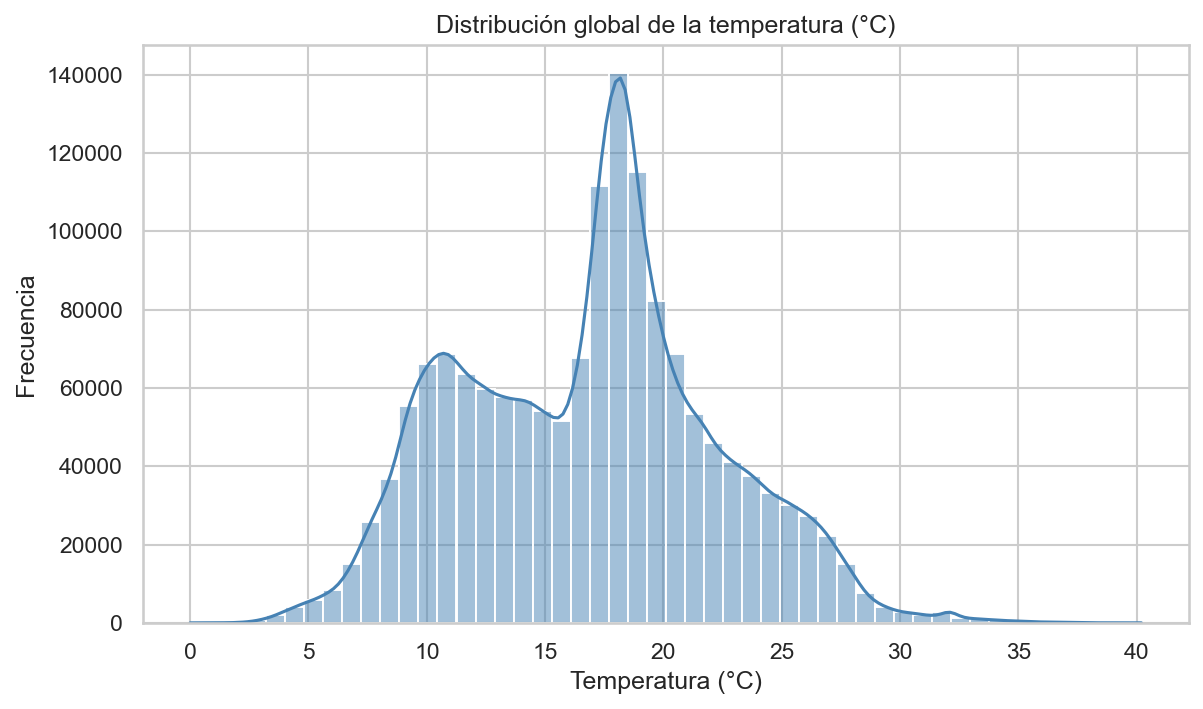

In [17]:
# ============================================================
# Figura 1: Histograma global de la temperatura (con KDE).
# ============================================================
fig, ax = plt.subplots(figsize=(9, 5))
sns.histplot(df_clean["temperatura"], kde=True, bins=50, color="steelblue", ax=ax)
ax.set_title("Distribución global de la temperatura (°C)")
ax.set_xlabel("Temperatura (°C)")
ax.set_ylabel("Frecuencia")
fig.savefig(FIGURES_DIR / "histograma_global.png")
plt.show()


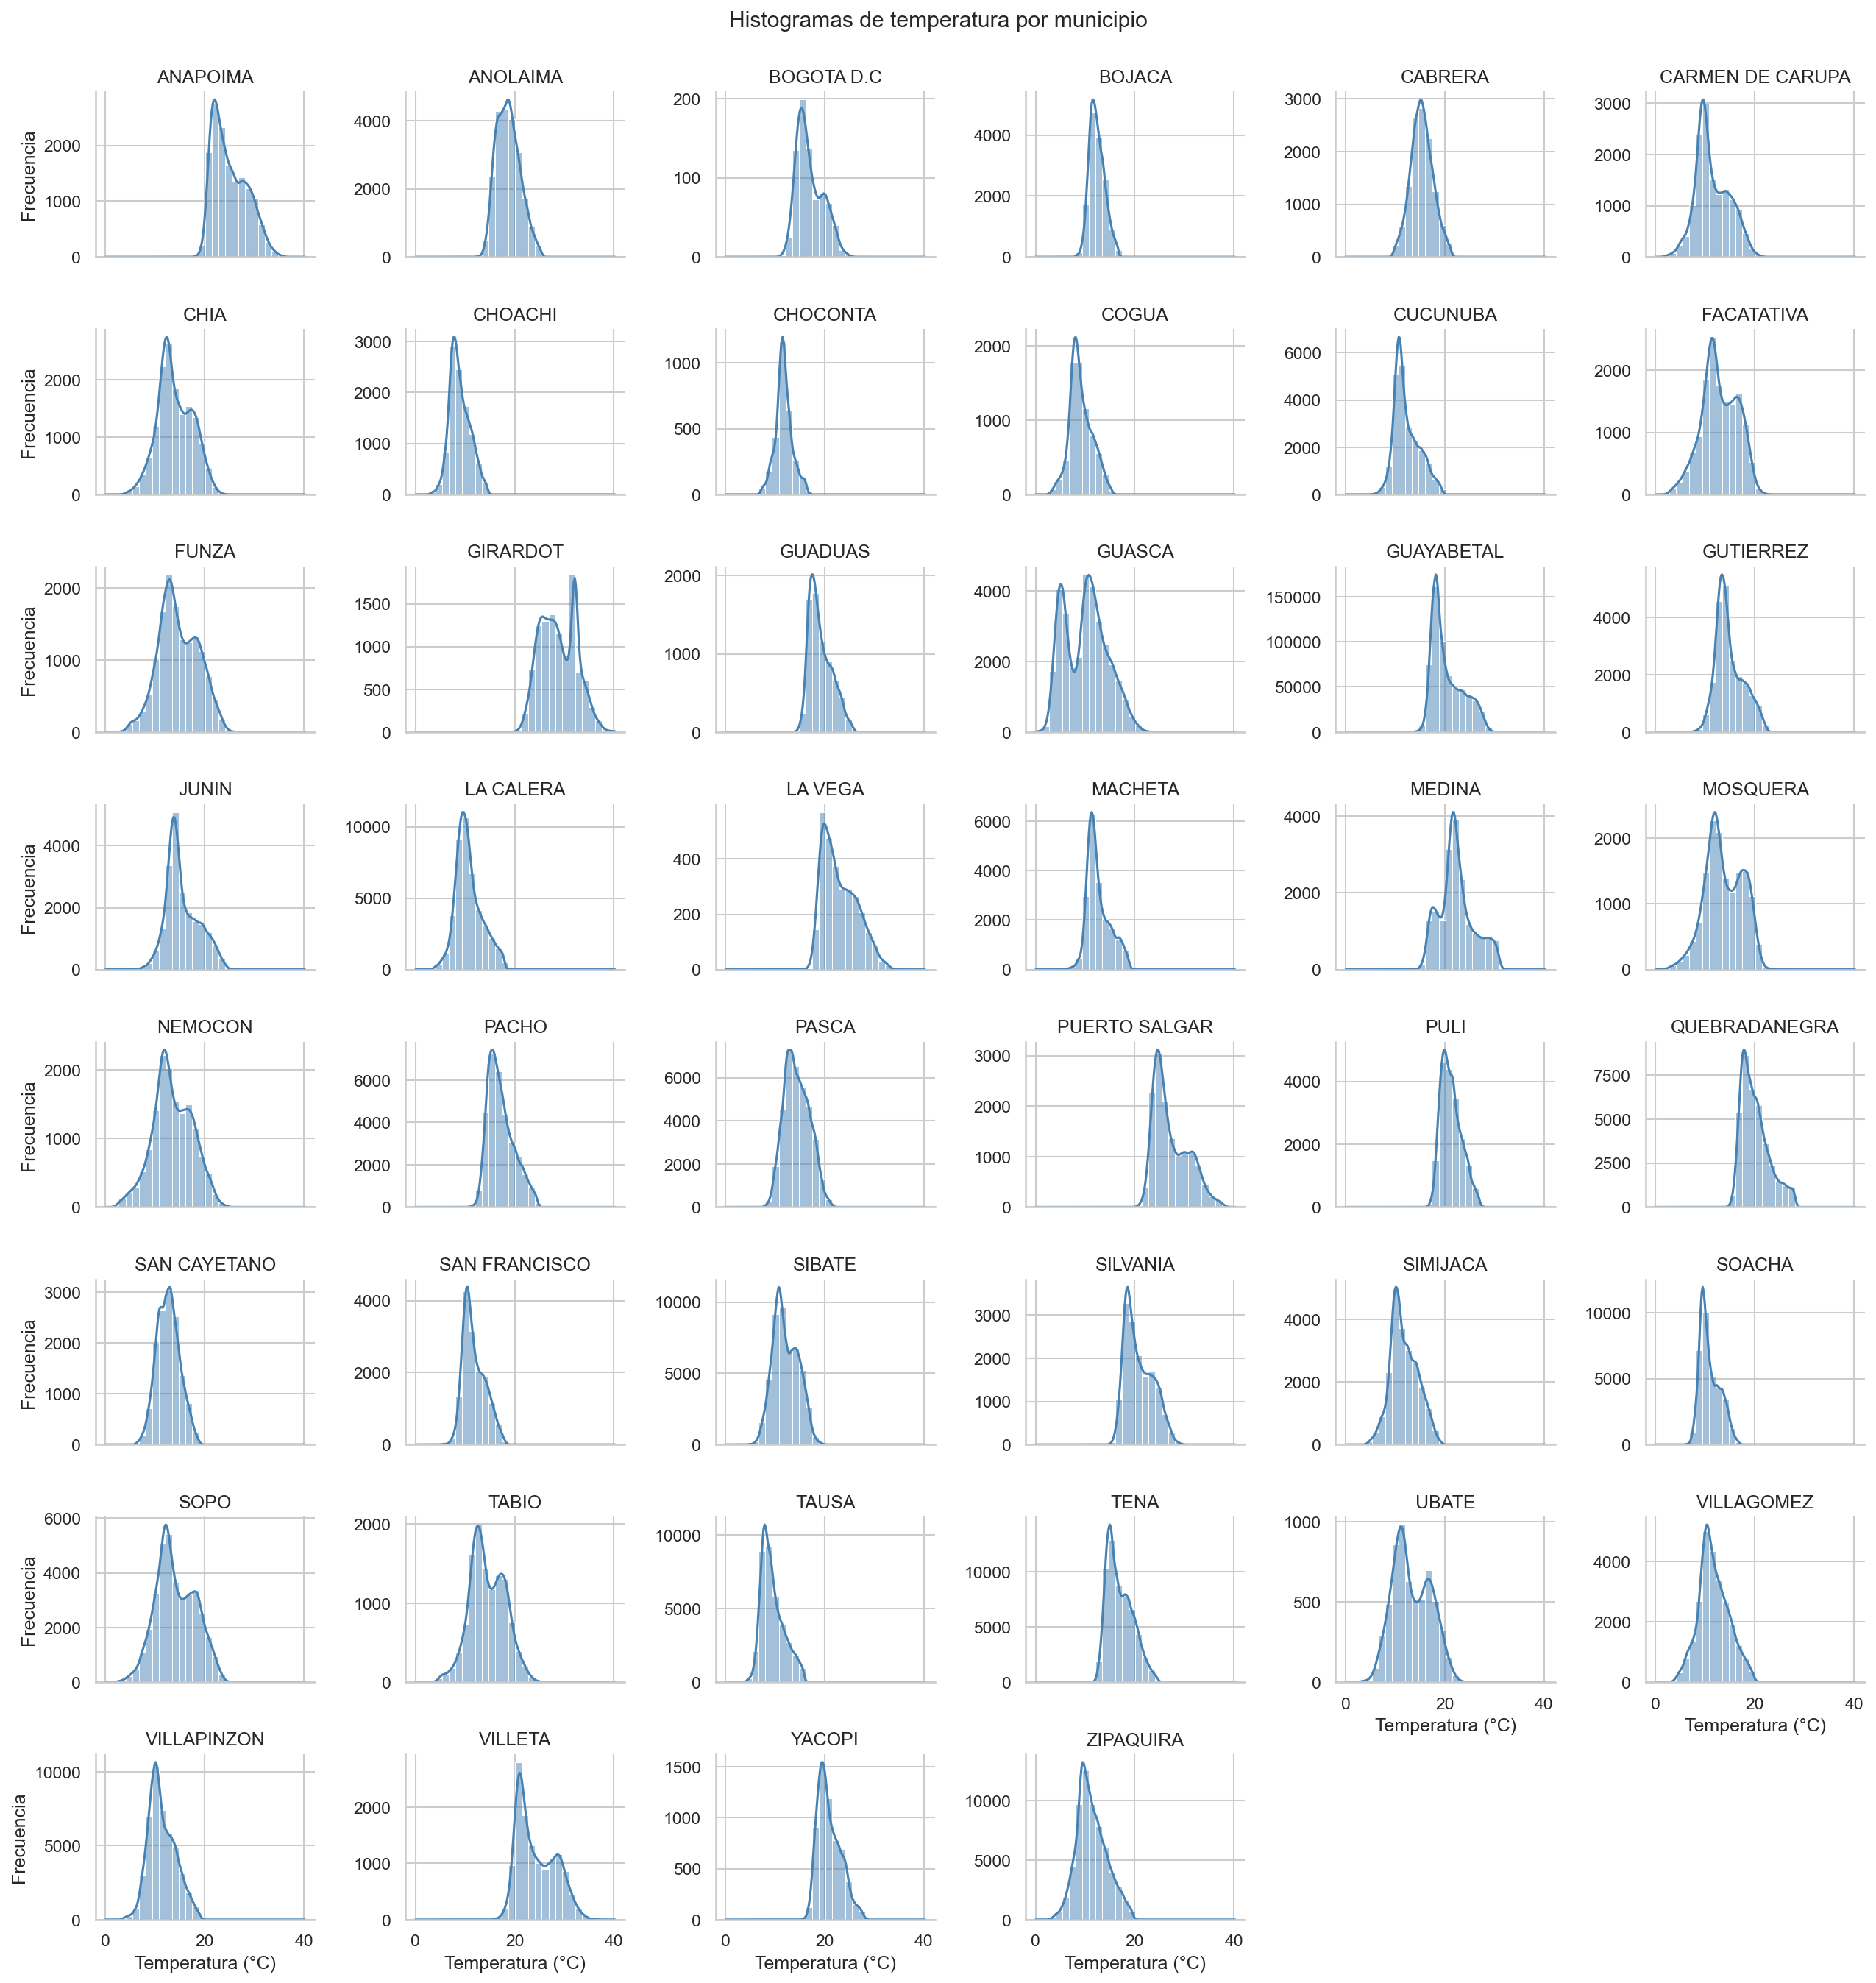

In [18]:
# ============================================================
# Figura 2: Histogramas por municipio (rejilla de subplots).
# ============================================================
munis = sorted(df_clean["municipio"].unique())
g = sns.displot(
    data=df_clean, x="temperatura", col="municipio", col_wrap=6,
    bins=30, kde=True, height=2.2, aspect=1.3, color="steelblue",
    col_order=munis, facet_kws={"sharex": True, "sharey": False},
)
g.set_axis_labels("Temperatura (°C)", "Frecuencia")
g.set_titles("{col_name}")
g.figure.suptitle("Histogramas de temperatura por municipio", y=1.02)
g.figure.savefig(FIGURES_DIR / "histogramas_por_municipio.png")
plt.show()


C:\Users\calde\AppData\Local\Temp\ipykernel_16040\1776016251.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_clean, x="temperatura", y="municipio", order=list(orden), palette="viridis", ax=ax)


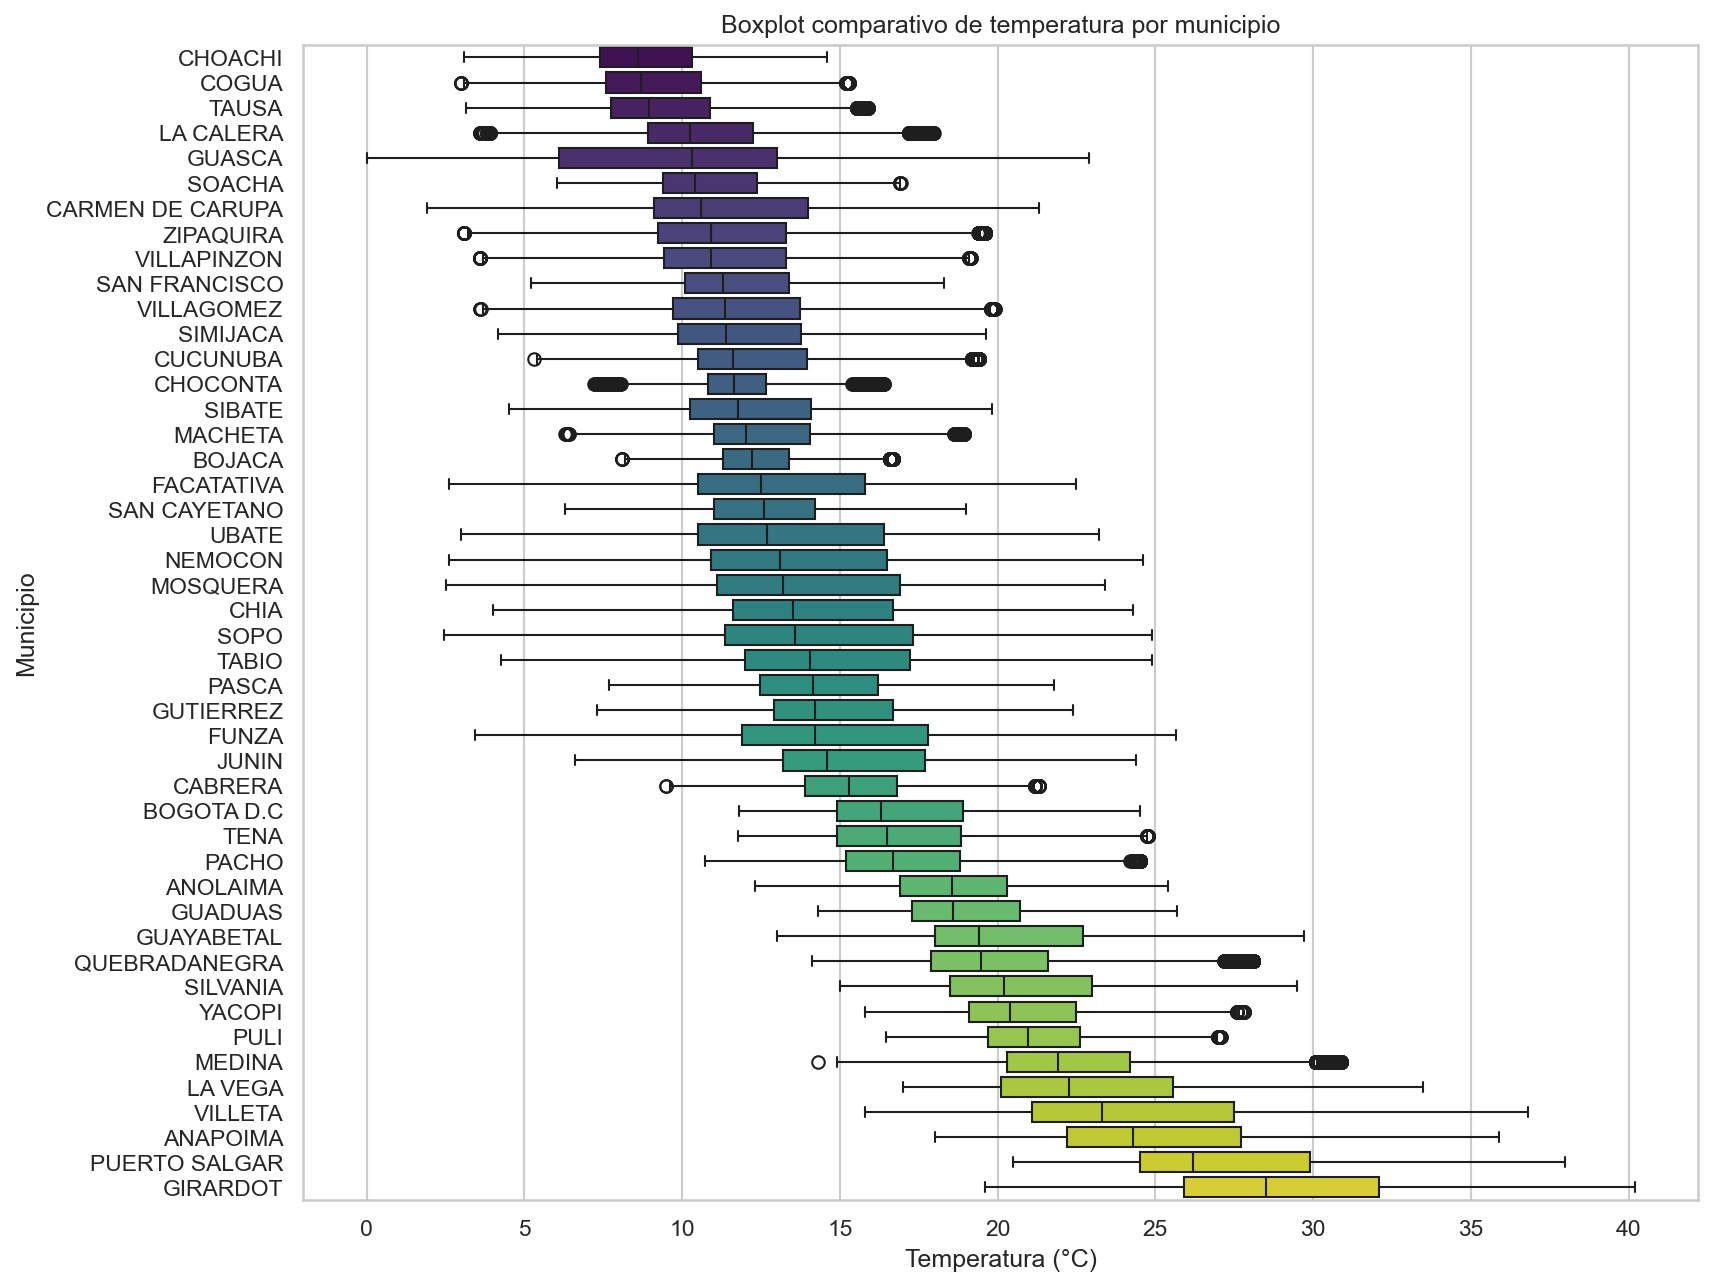

In [19]:
# ============================================================
# Figura 3: Boxplot comparativo de temperatura por municipio
# (ordenado por mediana).
# ============================================================
orden = df_clean.groupby("municipio")["temperatura"].median().sort_values().index
fig, ax = plt.subplots(figsize=(12, 10))
sns.boxplot(data=df_clean, x="temperatura", y="municipio", order=list(orden), palette="viridis", ax=ax)
ax.set_title("Boxplot comparativo de temperatura por municipio")
ax.set_xlabel("Temperatura (°C)")
ax.set_ylabel("Municipio")
fig.savefig(FIGURES_DIR / "boxplot_por_municipio.png")
plt.show()


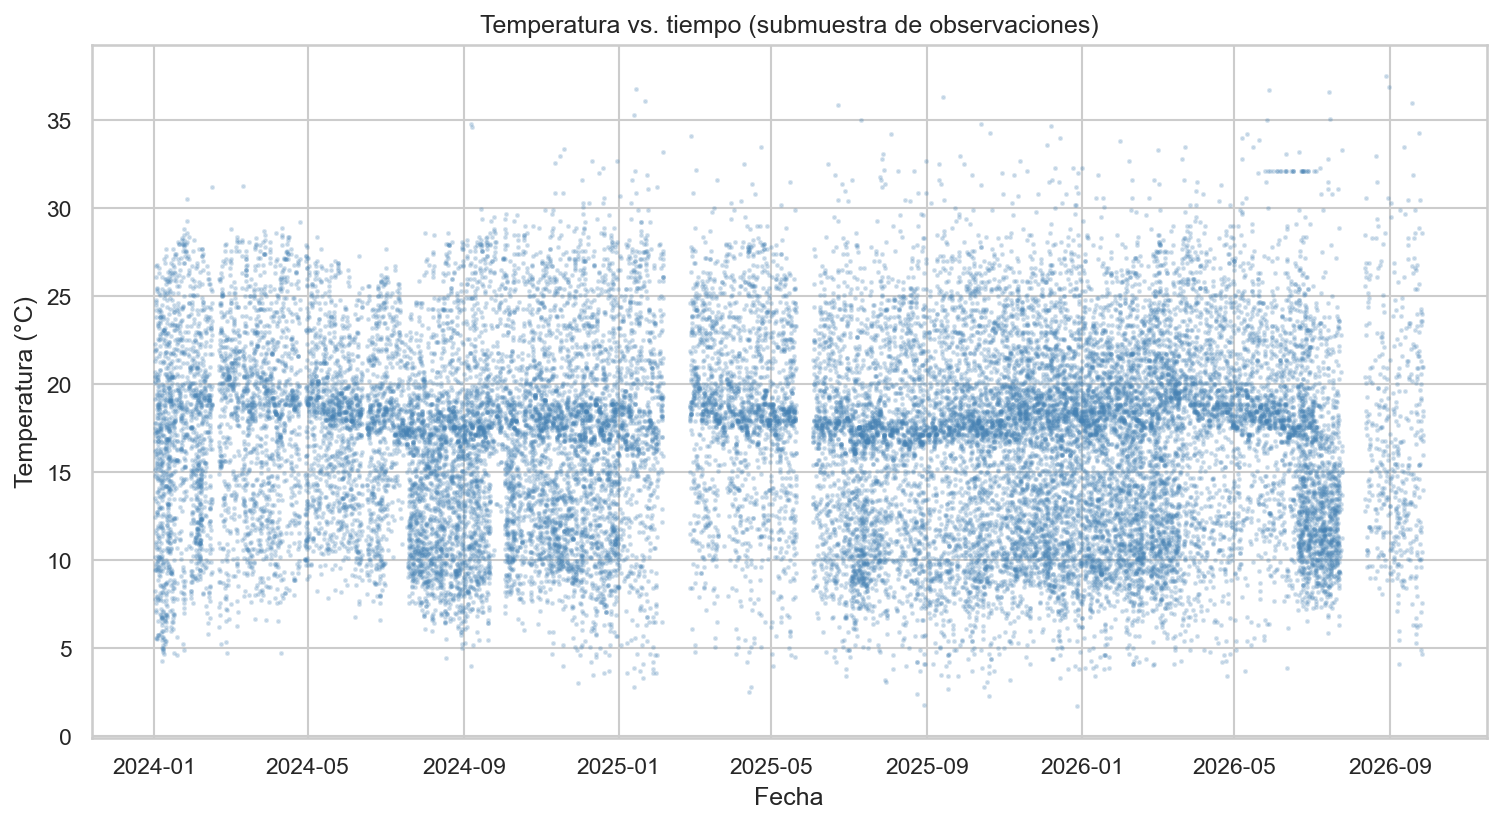

In [20]:
# ============================================================
# Figura 4: Dispersión temperatura vs. tiempo (submuestra aleatoria
# para no saturar el gráfico).
# ============================================================
muestra = df_clean.sample(n=min(30000, len(df_clean)), random_state=RANDOM_STATE)
fig, ax = plt.subplots(figsize=(12, 6))
ax.scatter(muestra["fecha"], muestra["temperatura"], s=2, alpha=0.2, c="steelblue")
ax.set_title("Temperatura vs. tiempo (submuestra de observaciones)")
ax.set_xlabel("Fecha")
ax.set_ylabel("Temperatura (°C)")
fig.savefig(FIGURES_DIR / "dispersion_temperatura_vs_tiempo.png")
plt.show()


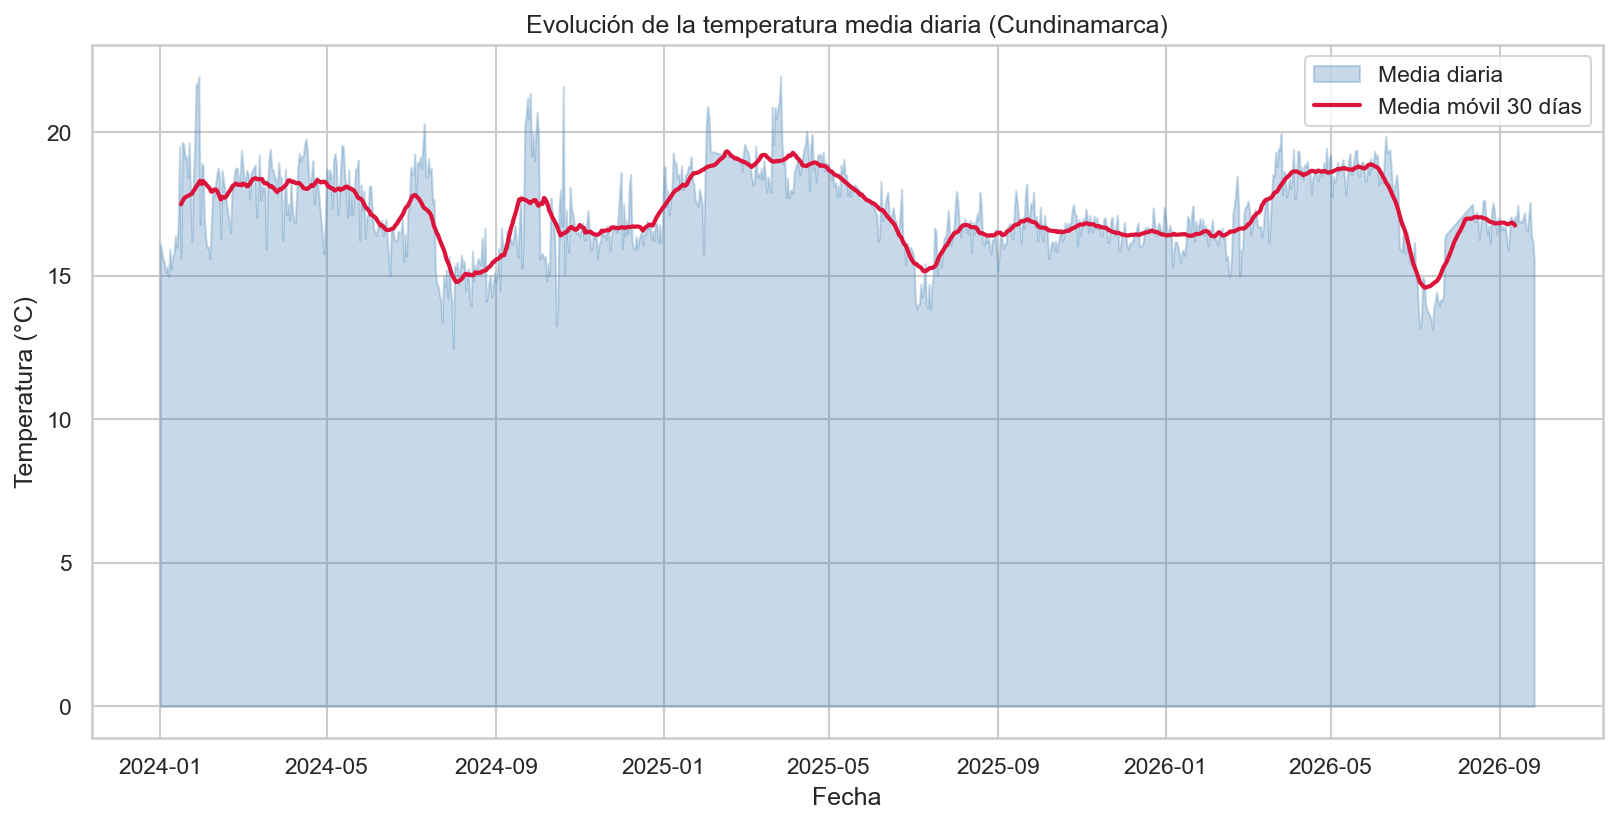

In [21]:
# ============================================================
# Figura 5: Serie temporal de la evolución agregada (área + media móvil).
# ============================================================
fig, ax = plt.subplots(figsize=(13, 6))
ax.fill_between(diario_completo.index, diario_completo.values, color="steelblue", alpha=0.3, label="Media diaria")
ax.plot(mm30.index, mm30.values, color="crimson", lw=2, label="Media móvil 30 días")
ax.set_title("Evolución de la temperatura media diaria (Cundinamarca)")
ax.set_xlabel("Fecha")
ax.set_ylabel("Temperatura (°C)")
ax.legend()
fig.savefig(FIGURES_DIR / "serie_temporal_media_diaria.png")
plt.show()


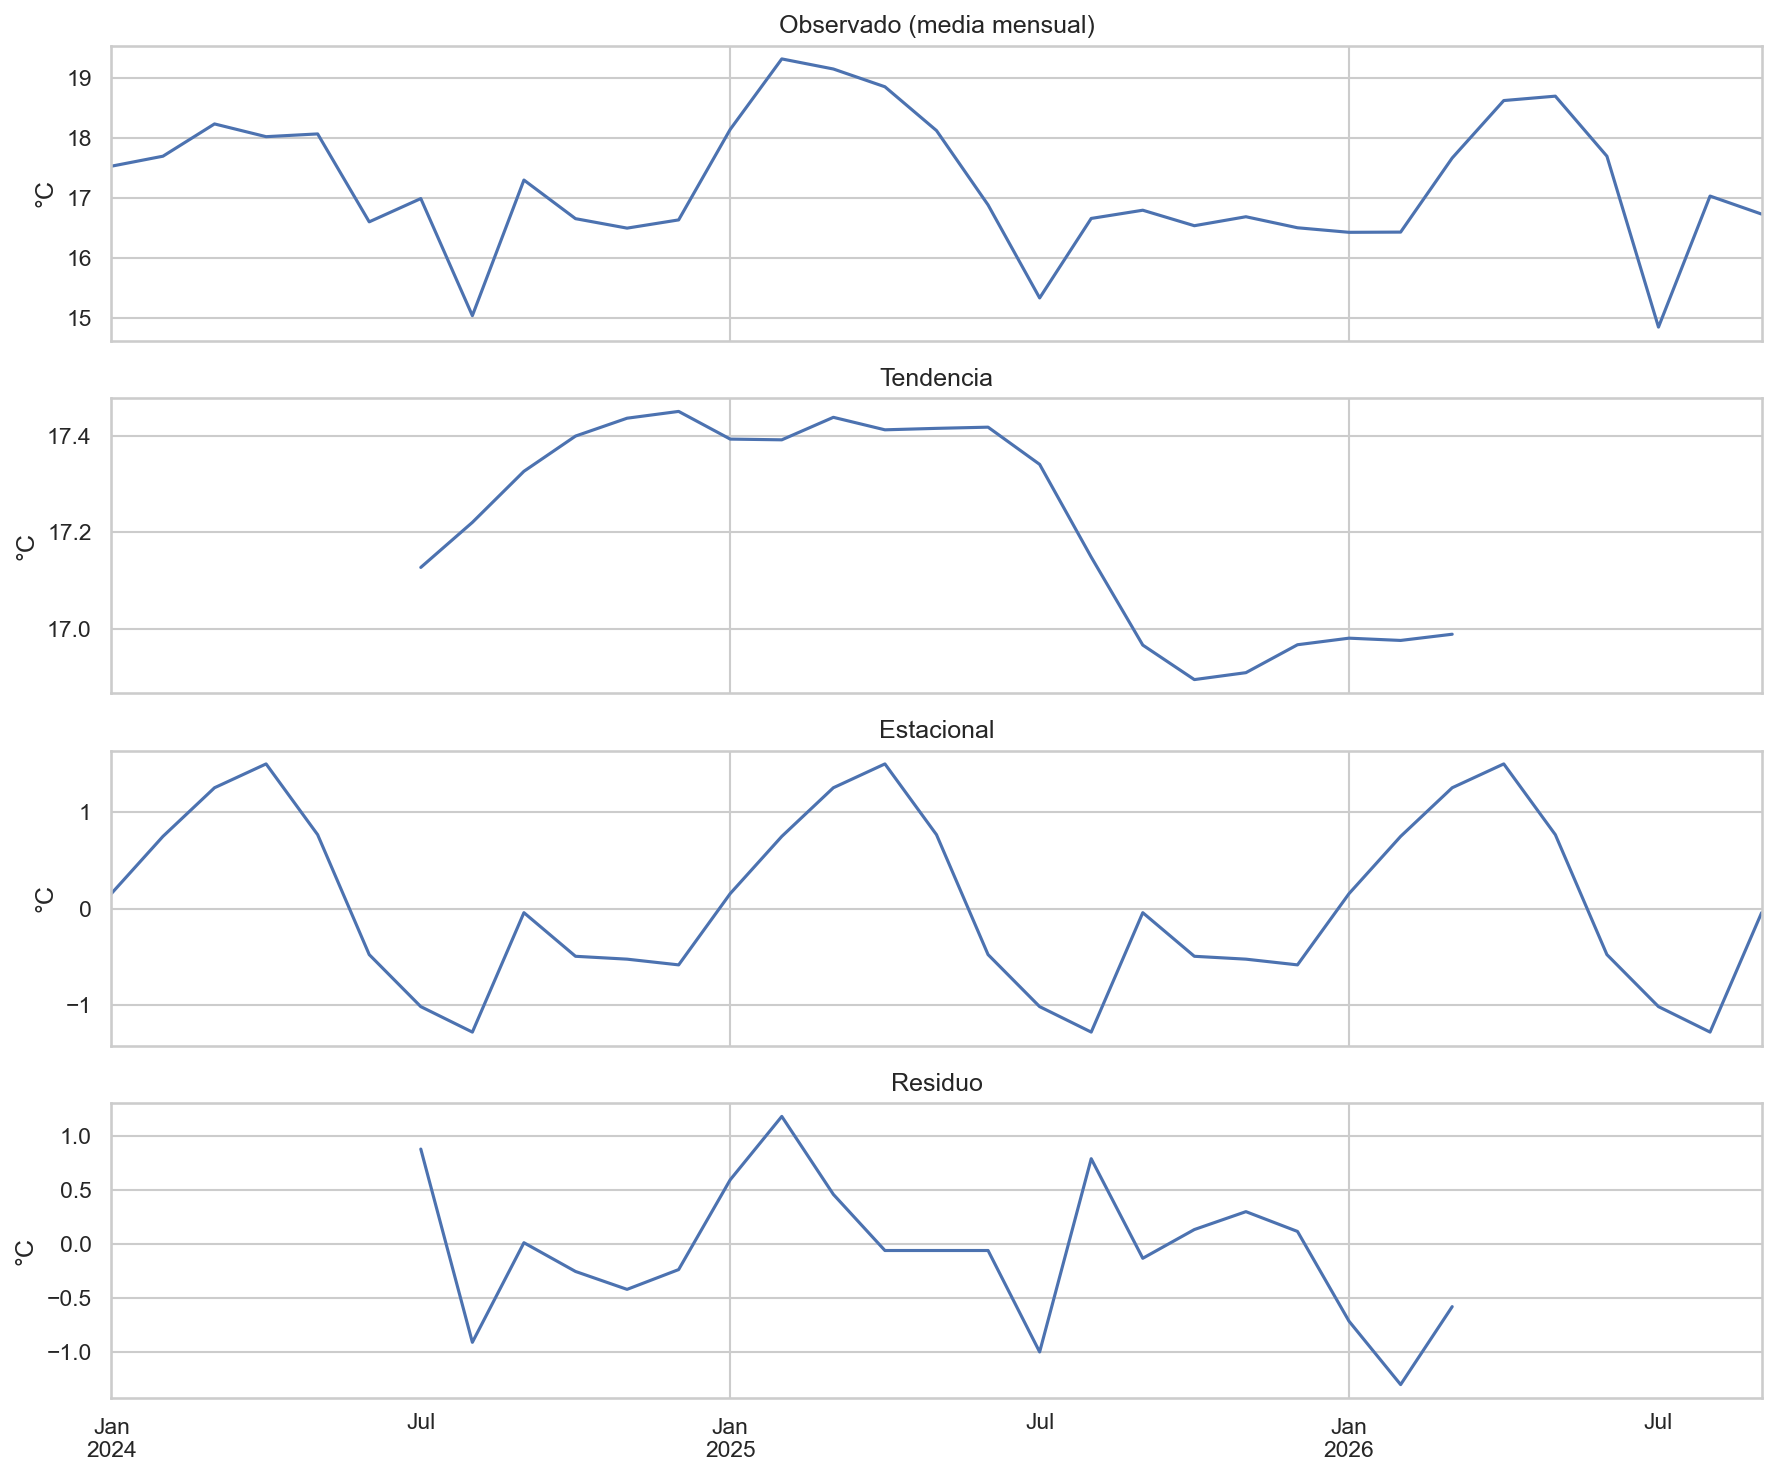

In [22]:
# ============================================================
# Figura 6: Descomposición estacional (observado, tendencia, estacional, residuo).
# ============================================================
fig, axes = plt.subplots(4, 1, figsize=(12, 10), sharex=True)
descomp.observed.plot(ax=axes[0], title="Observado (media mensual)")
descomp.trend.plot(ax=axes[1], title="Tendencia")
descomp.seasonal.plot(ax=axes[2], title="Estacional")
descomp.resid.plot(ax=axes[3], title="Residuo")
for ax_ in axes:
    ax_.set_ylabel("°C")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "descomposicion_estacional.png")
plt.show()


## 6. Conclusiones técnicas

Síntesis numérica de los resultados del análisis (sin interpretación narrativa
extensa).


In [23]:
# ============================================================
# Conclusiones técnicas (síntesis numérica).
# ============================================================
print("=" * 60)
print("CONCLUSIONES TÉCNICAS")
print("=" * 60)
print(f"Dataset limpio  : {len(df_clean)} observaciones, "
      f"{df_clean['municipio'].nunique()} municipios, "
      f"{df_clean['CodigoEstacion'].nunique()} estaciones")
print(f"Periodo         : {df_clean['fecha'].min().date()} a {df_clean['fecha'].max().date()}")
print(f"Temperatura     : media={df_clean['temperatura'].mean():.2f} °C, "
      f"mediana={df_clean['temperatura'].median():.2f} °C, "
      f"sd={df_clean['temperatura'].std():.2f} °C")
print(f"Municipio más cálido (media): {stats_mun['media'].idxmax()} ({stats_mun['media'].max():.2f} °C)")
print(f"Municipio más frío   (media): {stats_mun['media'].idxmin()} ({stats_mun['media'].min():.2f} °C)")
print(f"Comparación de grupos: {prueba}; estadístico={stat:.4f}; p-valor={p:.3e}")
if p < 0.05:
    print("  -> Diferencias significativas de temperatura entre municipios (p < 0.05)")
else:
    print("  -> Sin diferencias significativas entre municipios (p >= 0.05)")
print(f"Tendencia lineal media diaria: {pendiente_anio:.3f} °C/año")
print("=" * 60)


CONCLUSIONES TÉCNICAS
Dataset limpio  : 1547801 observaciones, 46 municipios, 59 estaciones
Periodo         : 2024-01-01 a 2026-09-26
Temperatura     : media=16.86 °C, mediana=17.40 °C, sd=5.40 °C
Municipio más cálido (media): GIRARDOT (28.84 °C)
Municipio más frío   (media): CHOACHI (8.91 °C)
Comparación de grupos: Kruskal-Wallis; estadístico=1092491.6402; p-valor=0.000e+00
  -> Diferencias significativas de temperatura entre municipios (p < 0.05)
Tendencia lineal media diaria: -0.218 °C/año


## 7. Análisis de resultados y conclusiones

A continuación se interpretan los resultados obtenidos en las celdas anteriores,
con base en las salidas reales de la ejecución.


### 7.1 Calidad de datos

- Se leyeron **1.800.319** registros crudos. No se detectaron nulos en `fecha` ni
  en `temperatura` (0 en ambas columnas).
- Se eliminaron **242.886** filas exactamente duplicadas (retransmisiones de los
  sensores) y **9.632** observaciones atípicas detectadas con el rango
  intercuartílico (IQR, factor 1.5) calculado **por municipio**.
- El dataset limpio final tiene **1.547.801** observaciones, **46 municipios** y
  **59 estaciones**, entre el 2024-01-01 y el 2026-09-26.
- La normalización de etiquetas redujo los municipios de **72 rótulos a 46
  únicos**, al unificar diferencias de mayúsculas y tildes (p.ej. `ANAPOIMA` y
  `Anapoima`), evitando dividir artificialmente los grupos.


### 7.2 Estadísticas descriptivas y dispersión

- **Global:** media = 16.86 °C, mediana = 17.40 °C, moda = 18.30 °C, desviación
  estándar = 5.40 °C, rango = 40.20 °C, IQR = 7.70 °C y coeficiente de variación
  (CV) = 0.32.
- La **moda** (18.30 °C) es poco informativa al tratarse de una variable continua:
  refleja un valor de alta frecuencia por redondeo del sensor.
- **Municipios más cálidos (media):** Girardot (28.84 °C), Puerto Salgar
  (27.25 °C), Anapoima (25.07 °C), Villeta (24.31 °C) y La Vega (23.03 °C), de
  clima cálido de vertiente/cuenca.
- **Municipios más fríos (media):** Choachí (8.91 °C), Cogua (9.12 °C), Tausa
  (9.47 °C), Guasca (10.10 °C) y La Calera (10.72 °C), de sabana alta.
- **Mayor variabilidad relativa (CV):** Guasca (0.421), Nemocón (0.292), Sopó
  (0.281), Ubaté (0.281) y Facatativá (0.280).
- **Menor variabilidad relativa (CV):** Pulí (0.096), Yacopí (0.111), Guaduas
  (0.119) y Bojacá/Girardot (0.124).


### 7.3 Comparación entre municipios

- El test de **Shapiro-Wilk** rechazó la hipótesis de normalidad en **los 46
  municipios** (p < 0.05 en todos), por lo que se aplicó la prueba no paramétrica
  de **Kruskal-Wallis**.
- Resultado: **H = 1.092.491,64** con **p-valor ≈ 0 (< 0.05)**. Se concluye que
  existen **diferencias estadísticamente significativas de temperatura entre
  municipios**.
- *Nota metodológica:* con ~1,55 millones de observaciones el test tiene una
  potencia muy alta, por lo que un p-valor extremadamente bajo es esperable; su
  magnitud práctica debe leerse junto con las medias por municipio de la sección
  7.2 (el gradiente térmico entre Girardot y Choachí supera los 19 °C).


### 7.4 Tendencia temporal

- Por **mes**, la media es máxima en abril (18.52 °C) y marzo (18.07 °C), y mínima
  en julio (15.19 °C), coherente con la estacionalidad bimodal andina.
- Por **estación climatológica**, Mar–May (lluvias) es la más cálida (18.29 °C) y
  Jun–Ago (seca) la más fría (15.95 °C).
- La **tendencia lineal** de la media diaria es −0.00060 °C/día
  (−0.218 °C/año), es decir, prácticamente plana: no se observa una tendencia
  relevante de calentamiento o enfriamiento dentro del periodo analizado.


### Conclusiones

1. La temperatura ambiente **difiere significativamente entre municipios**
   (Kruskal-Wallis, p ≈ 0), asociada al gradiente de altitud y clima del
   departamento.
2. Los extremos del gradiente térmico son los municipios cálidos de vertiente
   (Girardot, Puerto Salgar, Anapoima, Villeta) y los fríos de sabana alta
   (Choachí, Cogua, Tausa, Guasca).
3. La variabilidad estacional/intradiaria es alta en Guasca, Nemocón, Sopó y
   Ubaté, aspecto relevante para la planificación agrícola y ambiental.
4. No existe una tendencia temporal relevante (≈ −0.22 °C/año); la variación
   dominante es de tipo estacional.
